<a href="https://colab.research.google.com/github/nursulfiani20-collab/TUGAS-KULIAH/blob/main/Tugas1_Estimasi_Titik_Interval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 1 – Estimasi Titik dan Interval, Jackknife, dan Bootstrap
Nama : Nur Sulfiani

NIM  : 251061012



**Soal:**
Carilah data sebanyak 100 sampel.
- **a.** Hitung nilai estimasi titik dan interval menggunakan distribusi Z dengan tingkat kesalahan 5%.
- **b.** Lakukan proses resampling menggunakan metode jackknife dan bootstrapping, hitung nilai rata-rata dari hasil resamplingnya. Untuk bootstrapping lakukan iterasi sebanyak 1000.

**Data yang dipakai:** variabel `mean radius` (rata-rata jari-jari inti sel) dari dataset *Breast Cancer Wisconsin (Diagnostic)* (UCI Machine Learning Repository, tersedia di `scikit-learn`). Dari 569 pengamatan diambil **100 sampel acak** (`random_state=42`).


## 0. Import Library

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer

plt.rcParams['figure.figsize'] = (8, 4.5)
np.set_printoptions(precision=4, suppress=True)

## 1. Persiapan Data (100 Sampel)

In [12]:
# Ambil populasi data (569 pasien), lalu ambil 100 sampel acak
populasi = load_breast_cancer(as_frame=True).frame['mean radius']
sampel = populasi.sample(n=100, random_state=42).reset_index(drop=True)

# --- OPSIONAL: pakai data sendiri (CSV) ---
# sampel = pd.read_csv('data_saya.csv')['nama_kolom'].head(100)

sampel.to_csv('data_100_sampel.csv', index=False, header=['mean_radius'])
x = sampel.values.astype(float)

print("Jumlah sampel  :", len(x))
print("Populasi (569) : mean =", round(populasi.mean(), 4))
sampel.describe().to_frame('mean_radius').T

Jumlah sampel  : 100
Populasi (569) : mean = 14.1273


,count,mean,std,min,25%,50%,75%,max
mean_radius,100.0,14.03807,3.438502,6.981,11.655,13.31,15.84,25.22


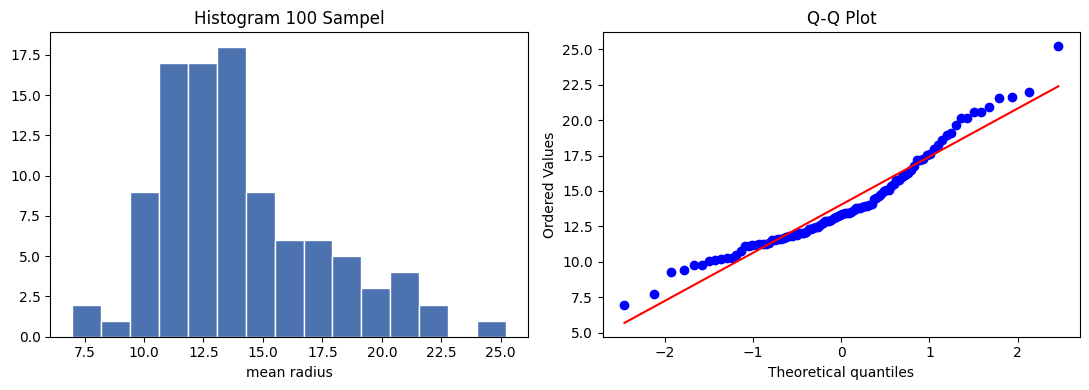

Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.9444334960654293), pvalue=np.float64(0.00036313142805292236))


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(x, bins=15, edgecolor='white', color='#4C72B0')
ax[0].set_title('Histogram 100 Sampel'); ax[0].set_xlabel('mean radius')
stats.probplot(x, dist='norm', plot=ax[1]); ax[1].set_title('Q-Q Plot')
plt.tight_layout(); plt.show()

print("Shapiro-Wilk:", stats.shapiro(x))

**Catatan asumsi:** Distribusi Z dipakai karena ukuran sampel besar ($n = 100 > 30$). Standar deviasi populasi ($\sigma$) tidak diketahui, sehingga diganti dengan standar deviasi sampel $s$ (aproksimasi yang wajar untuk $n$ besar). Berdasarkan teorema limit pusat, distribusi rata-rata sampel mendekati normal walaupun data aslinya sedikit menceng.

## 2. Soal (a): Estimasi Titik dan Interval dengan Distribusi Z

**Estimasi titik** untuk rata-rata populasi:
$$\hat{\mu} = \bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$

**Estimasi interval** (selang kepercayaan $(1-\alpha)100\%$) dengan $\alpha = 5\% = 0{,}05$:
$$\bar{x} - Z_{\alpha/2}\frac{s}{\sqrt{n}} \;<\; \mu \;<\; \bar{x} + Z_{\alpha/2}\frac{s}{\sqrt{n}}$$

In [14]:
n      = len(x)
alpha  = 0.05
x_bar  = x.mean()                 # estimasi titik
s      = x.std(ddof=1)            # simpangan baku sampel
se     = s / np.sqrt(n)           # standard error
z      = stats.norm.ppf(1 - alpha/2)   # Z_{alpha/2}
moe    = z * se                   # margin of error
bawah, atas = x_bar - moe, x_bar + moe

print(f"n                       = {n}")
print(f"Rata-rata sampel (x̄)    = {x_bar:.4f}   <- estimasi titik")
print(f"Simpangan baku (s)      = {s:.4f}")
print(f"Standard error (s/√n)   = {se:.4f}")
print(f"Z_(α/2) untuk α = 5%    = {z:.4f}")
print(f"Margin of error         = {moe:.4f}")
print(f"Interval kepercayaan 95%: {bawah:.4f} < μ < {atas:.4f}")
print(f"\nCek: rata-rata populasi sebenarnya = {populasi.mean():.4f} "
      f"-> {'berada di dalam' if bawah < populasi.mean() < atas else 'di luar'} interval")

n                       = 100
Rata-rata sampel (x̄)    = 14.0381   <- estimasi titik
Simpangan baku (s)      = 3.4385
Standard error (s/√n)   = 0.3439
Z_(α/2) untuk α = 5%    = 1.9600
Margin of error         = 0.6739
Interval kepercayaan 95%: 13.3641 < μ < 14.7120

Cek: rata-rata populasi sebenarnya = 14.1273 -> berada di dalam interval


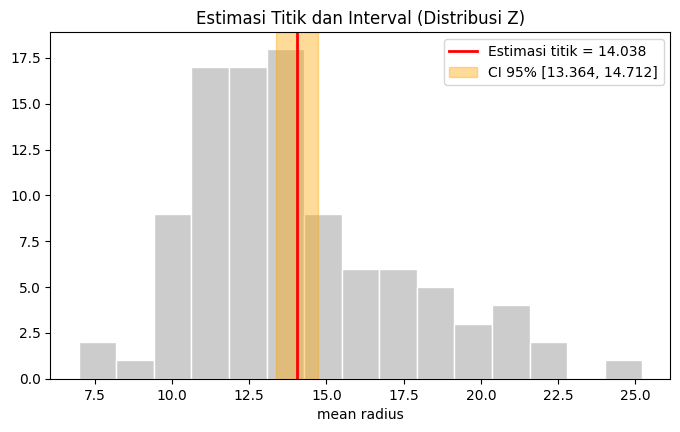

In [15]:
# Visualisasi interval kepercayaan
fig, ax = plt.subplots()
ax.hist(x, bins=15, color='#CCCCCC', edgecolor='white')
ax.axvline(x_bar, color='red', lw=2, label=f'Estimasi titik = {x_bar:.3f}')
ax.axvspan(bawah, atas, color='orange', alpha=0.4, label=f'CI 95% [{bawah:.3f}, {atas:.3f}]')
ax.set_title('Estimasi Titik dan Interval (Distribusi Z)')
ax.set_xlabel('mean radius'); ax.legend(); plt.show()

**Interpretasi (a):** Estimasi titik rata-rata `mean radius` populasi adalah $\bar{x}$ di atas. Dengan tingkat kesalahan 5% (kepercayaan 95%), rata-rata populasi diyakini berada di dalam interval yang dihitung.

## 3. Soal (b): Resampling

### 3.1 Metode Jackknife (leave-one-out)

Misalkan $\hat\theta$ = estimator pada seluruh data, $\hat\theta_{(i)}$ = estimator setelah observasi ke-$i$ dihapus, dan $\bar{\theta}_{(\cdot)} = \frac{1}{n}\sum_i \hat\theta_{(i)}$.

- Estimasi bias (Tukey): $\widehat{Bias}_J = (n-1)(\bar\theta_{(\cdot)} - \hat\theta)$
- Estimator terkoreksi bias: $\hat\theta_J = \hat\theta - \widehat{Bias}_J = n\hat\theta - (n-1)\bar\theta_{(\cdot)}$
- Standard error: $SE_J = \sqrt{\frac{n-1}{n}\sum_{i=1}^{n}(\hat\theta_{(i)} - \bar\theta_{(\cdot)})^2}$

In [16]:
def jackknife(func, data):
    data = np.asarray(data)
    n = data.shape[0]
    thetas = np.array([func(np.delete(data, i, axis=0)) for i in range(n)])
    theta_hat = func(data)
    theta_bar = thetas.mean()                      # rata-rata hasil resampling
    bias_hat  = (n - 1) * (theta_bar - theta_hat)
    theta_j   = n * theta_hat - (n - 1) * theta_bar
    se_j      = np.sqrt(((n - 1) / n) * np.sum((thetas - theta_bar) ** 2))
    return dict(theta_hat=theta_hat, thetas=thetas, theta_bar=theta_bar,
                bias_hat=bias_hat, theta_j=theta_j, se_j=se_j)

jk = jackknife(np.mean, x)

print(f"Jumlah resampel jackknife (n)       = {len(jk['thetas'])}")
print(f"Estimasi pada seluruh data (θ̂)      = {jk['theta_hat']:.4f}")
print(f"RATA-RATA hasil jackknife (θ̄(.))    = {jk['theta_bar']:.4f}")
print(f"Estimasi bias jackknife             = {jk['bias_hat']:.6f}")
print(f"Estimator terkoreksi bias (θ̂_J)     = {jk['theta_j']:.4f}")
print(f"Standard error jackknife            = {jk['se_j']:.4f}")
print(f"Pembanding SE analitik (s/√n)       = {se:.4f}")

Jumlah resampel jackknife (n)       = 100
Estimasi pada seluruh data (θ̂)      = 14.0381
RATA-RATA hasil jackknife (θ̄(.))    = 14.0381
Estimasi bias jackknife             = 0.000000
Estimator terkoreksi bias (θ̂_J)     = 14.0381
Standard error jackknife            = 0.3439
Pembanding SE analitik (s/√n)       = 0.3439


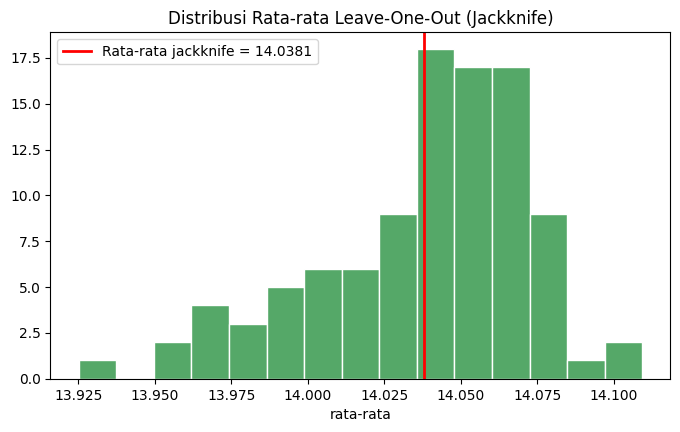

In [17]:
plt.hist(jk['thetas'], bins=15, color='#55A868', edgecolor='white')
plt.axvline(jk['theta_bar'], color='red', lw=2, label=f"Rata-rata jackknife = {jk['theta_bar']:.4f}")
plt.title('Distribusi Rata-rata Leave-One-Out (Jackknife)')
plt.xlabel('rata-rata'); plt.legend(); plt.show()

### 3.2 Metode Bootstrap (1000 iterasi)

Bootstrap mensimulasikan ulang sampel dengan **pengambilan acak berukuran $n$ dengan pengembalian** dari data asli (distribusi empirik, tiap observasi berpeluang $1/n$). Pada tiap iterasi dihitung rata-ratanya sehingga diperoleh 1000 rata-rata bootstrap.

In [18]:
def bootstrap(func, data, B=1000, seed=42):
    rng = np.random.default_rng(seed)
    data = np.asarray(data)
    n = len(data)
    return np.array([func(rng.choice(data, size=n, replace=True)) for _ in range(B)])

B = 1000
boot_means = bootstrap(np.mean, x, B=B)

boot_mean = boot_means.mean()                 # rata-rata hasil resampling
boot_se   = boot_means.std(ddof=1)
boot_bias = boot_mean - x_bar
ci_perc   = np.percentile(boot_means, [2.5, 97.5])

print(f"Jumlah iterasi bootstrap            = {B}")
print(f"Estimasi pada data asli (x̄)         = {x_bar:.4f}")
print(f"RATA-RATA hasil bootstrap           = {boot_mean:.4f}")
print(f"Bias bootstrap (rata-rata boot - x̄) = {boot_bias:.4f}")
print(f"Standard error bootstrap            = {boot_se:.4f}")
print(f"CI 95% bootstrap (persentil)        = [{ci_perc[0]:.4f}, {ci_perc[1]:.4f}]")

Jumlah iterasi bootstrap            = 1000
Estimasi pada data asli (x̄)         = 14.0381
RATA-RATA hasil bootstrap           = 14.0340
Bias bootstrap (rata-rata boot - x̄) = -0.0041
Standard error bootstrap            = 0.3513
CI 95% bootstrap (persentil)        = [13.3883, 14.7353]


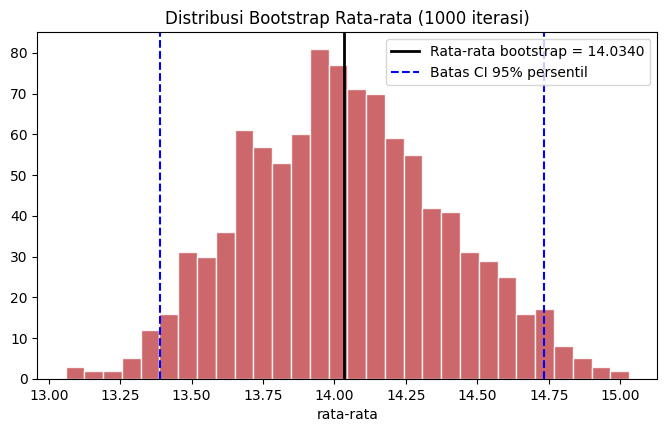

In [19]:
plt.hist(boot_means, bins=30, color='#C44E52', edgecolor='white', alpha=0.85)
plt.axvline(boot_mean, color='black', lw=2, label=f'Rata-rata bootstrap = {boot_mean:.4f}')
plt.axvline(ci_perc[0], color='blue', ls='--', label='Batas CI 95% persentil')
plt.axvline(ci_perc[1], color='blue', ls='--')
plt.title(f'Distribusi Bootstrap Rata-rata ({B} iterasi)')
plt.xlabel('rata-rata'); plt.legend(); plt.show()

## 4. Rekapitulasi Hasil

In [20]:
rekap = pd.DataFrame({
    'Metode': ['Z (analitik)', 'Jackknife (n = 100)', 'Bootstrap (B = 1000)'],
    'Rata-rata / Estimasi': [x_bar, jk['theta_bar'], boot_mean],
    'Standard Error': [se, jk['se_j'], boot_se],
    'Batas Bawah CI 95%': [bawah, np.nan, ci_perc[0]],
    'Batas Atas CI 95%': [atas, np.nan, ci_perc[1]],
}).round(4)
rekap

,Metode,Rata-rata / Estimasi,Standard Error,Batas Bawah CI 95%,Batas Atas CI 95%
0,Z (analitik),14.0381,0.3439,13.3641,14.7120
1,Jackknife (n = 100),14.0381,0.3439,NaN,NaN
2,Bootstrap (B = 1000),14.0340,0.3513,13.3883,14.7353


## 5. Kesimpulan

1. **Estimasi titik** rata-rata `mean radius` adalah $\bar{x}$ (lihat tabel), dan **estimasi interval 95%** dengan distribusi Z ($Z_{0{,}025} = 1{,}96$) memberikan selang kepercayaan seperti pada bagian 2.
2. **Jackknife:** rata-rata dari 100 estimasi leave-one-out **sama dengan rata-rata sampel** (bias = 0). Hal ini wajar karena rata-rata adalah estimator tak bias, dan standard error jackknife identik dengan $s/\sqrt{n}$.
3. **Bootstrap (1000 iterasi):** rata-rata hasil resampling **sangat dekat** dengan rata-rata sampel (selisih kecil akibat variasi acak), dan standard error serta CI persentil bootstrap hampir sama dengan hasil metode Z.
4. Ketiga metode memberikan hasil yang konsisten, sehingga estimasi rata-rata ini dapat dipercaya. Metode resampling berguna terutama saat distribusi data tidak diketahui atau estimatornya tidak punya rumus analitik sederhana.